# Friday → Monday follow-through on Nifty 50

**The idea:** if Friday closes green (or red), does Monday tend to close the *same* colour?
If it does often enough, we can trade it: **BUY** after a green Friday, **SELL** after a red Friday.

This notebook answers five questions:

1. Does a green Friday lead to a green Monday (and red to red)?
2. How did the simple strategy do over the whole data set?
3. Which factors (e.g. *red Friday + Friday volume > Thursday volume*) improve the odds?
4. Do those factors survive an honest out-of-sample check?
5. How did the strategy do in each 5-year block vs **Nifty buy-and-hold**?

**Definitions used throughout**

| Term | Meaning |
|---|---|
| Green / Red candle | Close > Open / Close < Open for that day |
| Follow-through | Monday's candle has the same colour as Friday's |
| Trade | Green Friday → BUY at Friday close. Red Friday → SELL (short) at Friday close. Exit at Monday close |
| Trade return | `direction × (Monday close / Friday close − 1)` in % (direction = +1 buy, −1 sell) |
| Win rate | % of trades with a positive net return |

Only weeks with a clean Thursday → Friday → Monday sequence are used (weeks with a Friday or Monday market holiday are skipped).

## 0. Setup and data loading

Put this notebook in the same folder as `NIFTY50.csv`. The file is newest-first, has commas in prices, and writes volume like `391.56M`, so we clean all of that first.

`COST_PCT` is the round-trip trading cost per trade in %. It starts at 0 so you can see the raw edge. Try 0.05 to 0.10 to see how costs change the picture.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

CSV_PATH = "NIFTY50.csv"
COST_PCT = 0.0        # round-trip cost per trade, in %
SPLIT_YEAR = 2012     # discovery period: <= this year, validation period: after it

In [2]:
def parse_volume(v):
    """'391.56M' -> 391560000.0, '-' or blank -> NaN"""
    if pd.isna(v) or str(v).strip() in ("", "-"):
        return np.nan
    v = str(v).replace(",", "").strip()
    mult = {"K": 1e3, "M": 1e6, "B": 1e9}.get(v[-1].upper(), 1)
    return float(v[:-1] if v[-1].upper() in "KMB" else v) * mult

df = pd.read_csv(CSV_PATH)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
for c in ["Open", "High", "Low", "Close"]:
    df[c] = df[c].astype(str).str.replace(",", "").astype(float)
df["Volume"] = df["Volume"].apply(parse_volume)
df = df.sort_values("Date").reset_index(drop=True)      # oldest first

print(f"{len(df):,} daily bars   {df.Date.min().date()}  ->  {df.Date.max().date()}")
print(f"Missing volume on {df.Volume.isna().sum()} days")
df.tail(3)

6,661 daily bars   2000-01-03  ->  2026-10-16
Missing volume on 6 days


,Date,Close,Open,High,Low,Volume
6658,2026-10-14,22622.70,22715.75,22757.95,22558.95,333250000.0
6659,2026-10-15,22997.35,22671.30,23056.40,22637.40,370770000.0
6660,2026-10-16,23146.15,23065.10,23149.60,22915.50,391560000.0


## 1. Build the daily features

Every feature below uses information available **at Friday's close**, so nothing peeks into Monday.

| Feature | What it measures |
|---|---|
| `volchg1` | Friday volume vs Thursday volume, in % |
| `relvol20` | Friday volume ÷ average volume of the previous 20 days |
| `body_pct` | Friday open-to-close move, in % |
| `gap_pct` | Friday open vs Thursday close, in % |
| `close_loc` | Where Friday closed inside its own range (0 = at the low, 1 = at the high) |
| `range_rel20` | Friday's high-low range vs its 20-day average |
| `dist_sma50` | Distance of Friday's close from the 50-day average, in % |
| `mom5` | 5-day return up to Friday's close, in % |

In [3]:
d = df.copy()
d["weekday"]    = d["Date"].dt.weekday                      # Mon=0 ... Fri=4
d["colour"]     = np.select([d.Close > d.Open, d.Close < d.Open], ["green", "red"], default="doji")
d["body_pct"]   = (d.Close / d.Open - 1) * 100
d["gap_pct"]    = (d.Open / d.Close.shift(1) - 1) * 100
d["close_loc"]  = (d.Close - d.Low) / (d.High - d.Low).replace(0, np.nan)
d["range_pct"]  = (d.High - d.Low) / d.Close * 100
d["range_rel20"] = d.range_pct / d.range_pct.rolling(20).mean().shift(1)
d["prev_vol"]   = d.Volume.shift(1)
d["volchg1"]    = (d.Volume / d.prev_vol - 1) * 100
d["relvol20"]   = d.Volume / d.Volume.rolling(20).mean().shift(1)
d["dist_sma50"] = (d.Close / d.Close.rolling(50).mean() - 1) * 100
d["mom5"]       = (d.Close / d.Close.shift(5) - 1) * 100
d["prev_colour"]  = d.colour.shift(1)
d["prev_weekday"] = d.weekday.shift(1)

# what happened on the next trading day
d["next_weekday"] = d.weekday.shift(-1)
d["next_date"]    = d.Date.shift(-1)
d["mon_colour"]   = d.colour.shift(-1)
d["mon_close"]    = d.Close.shift(-1)

# keep only clean Thu -> Fri -> Mon weeks
ok = ((d.weekday == 4) & (d.prev_weekday == 3) & (d.next_weekday == 0)
      & ((d.next_date - d.Date).dt.days == 3)
      & d.colour.isin(["green", "red"]) & d.mon_colour.isin(["green", "red"]))
w = d[ok].copy()

w["year"]      = w.Date.dt.year
w["follow"]    = w.colour == w.mon_colour
w["direction"] = np.where(w.colour == "green", 1, -1)           # BUY after green, SELL after red
w["long_ret"]  = (w.mon_close / w.Close - 1) * 100              # plain Fri close -> Mon close
w["gross_ret"] = w.direction * w.long_ret
w["net_ret"]   = w.gross_ret - COST_PCT
w["win"]       = w.net_ret > 0

# "aligned" versions: positive = in the direction of Friday's colour
w["body_size"]      = w.body_pct.abs()
w["gap_aligned"]    = w.direction * w.gap_pct
w["close_strength"] = np.where(w.colour == "green", w.close_loc, 1 - w.close_loc)   # 1 = closed at Friday's extreme
w["trend_aligned"]  = w.direction * w.dist_sma50
w["mom5_aligned"]   = w.direction * w.mom5
w["thu_same"]       = w.prev_colour == w.colour

print(f"Usable Thu/Fri/Mon weeks: {len(w)}   (green Fridays: {(w.colour=='green').sum()}, red Fridays: {(w.colour=='red').sum()})")

Usable Thu/Fri/Mon weeks: 1160   (green Fridays: 583, red Fridays: 577)


## 2. Does a green Friday lead to a green Monday?

We compare two things:

- **P(Monday green | Friday green)** vs **P(Monday green | Friday red)**
- The unconditional chance that *any* Monday is green

If Friday's colour carries information, the first number should be clearly higher than the second. A **chi-square test** checks whether Friday's colour and Monday's colour are independent. A small p-value means they are *not* independent.

,weeks,Monday green %,Monday red %,Monday same colour %
Green Friday,583,55.2,44.8,55.2
Red Friday,577,45.8,54.2,54.2


Share of ALL Mondays that close green: 50.8%
Chi-square test (Friday colour vs Monday colour): p = 0.0015


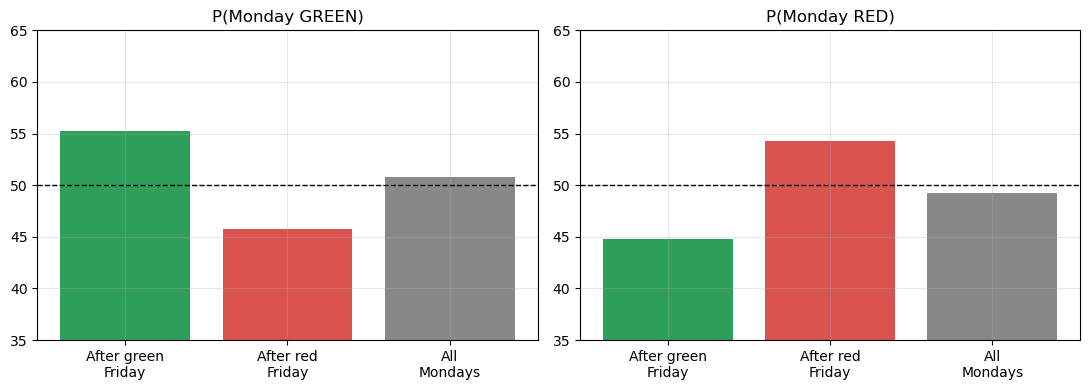

In [4]:
all_mondays_green = (d[d.weekday == 0].colour == "green").mean() * 100

tab = pd.crosstab(w.colour, w.mon_colour)
chi2, p_chi, _, _ = stats.chi2_contingency(tab)

summary = pd.DataFrame({
    "weeks":                  w.groupby("colour").size(),
    "Monday green %":         w.groupby("colour").apply(lambda g: (g.mon_colour == "green").mean() * 100),
    "Monday red %":           w.groupby("colour").apply(lambda g: (g.mon_colour == "red").mean() * 100),
    "Monday same colour %":   w.groupby("colour").follow.mean() * 100,
}).round(1)
summary.index = [f"{i.title()} Friday" for i in summary.index]
display(summary)
print(f"Share of ALL Mondays that close green: {all_mondays_green:.1f}%")
print(f"Chi-square test (Friday colour vs Monday colour): p = {p_chi:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
g = w[w.colour == "green"]; r = w[w.colour == "red"]
ax[0].bar(["After green\nFriday", "After red\nFriday", "All\nMondays"],
          [(g.mon_colour == "green").mean() * 100, (r.mon_colour == "green").mean() * 100, all_mondays_green],
          color=["#2e9e5b", "#d9534f", "#888"])
ax[0].axhline(50, ls="--", c="k", lw=1); ax[0].set_ylim(35, 65); ax[0].set_title("P(Monday GREEN)")
ax[1].bar(["After green\nFriday", "After red\nFriday", "All\nMondays"],
          [(g.mon_colour == "red").mean() * 100, (r.mon_colour == "red").mean() * 100, 100 - all_mondays_green],
          color=["#2e9e5b", "#d9534f", "#888"])
ax[1].axhline(50, ls="--", c="k", lw=1); ax[1].set_ylim(35, 65); ax[1].set_title("P(Monday RED)")
plt.tight_layout(); plt.show()

**How to read this:** compare the green bar with the red bar in the left chart. If a green Friday leads to a green Monday, the left green bar sits above the left red bar. The right chart is the mirror image for red Mondays. Bars near the dashed 50% line mean no real edge.

Next, is the pattern **stable over time**, or does it come from a few years?

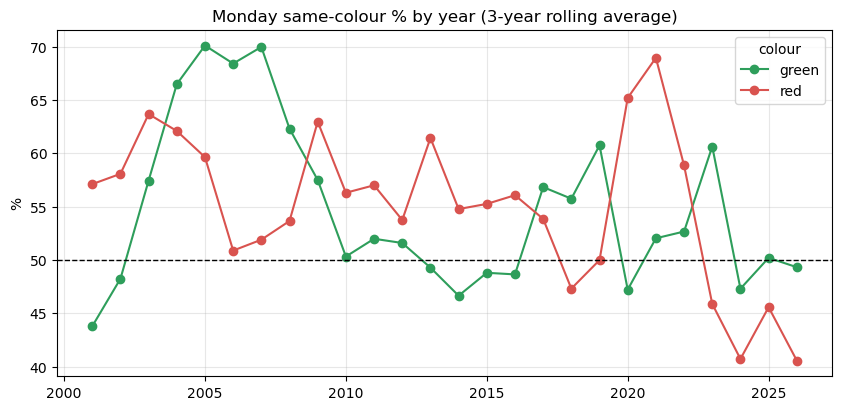

In [5]:
yearly = w.groupby(["year", "colour"]).follow.mean().unstack() * 100
roll = yearly.rolling(3, min_periods=2).mean()

ax = roll.plot(color={"green": "#2e9e5b", "red": "#d9534f"}, marker="o")
ax.axhline(50, ls="--", c="k", lw=1)
ax.set_title("Monday same-colour % by year (3-year rolling average)")
ax.set_ylabel("%"); ax.set_xlabel("")
plt.show()

## 3. The strategy on the full data set

Rules (no filters yet):

- Friday closes **green** → BUY at Friday close, exit Monday close
- Friday closes **red** → SELL at Friday close, exit Monday close

`perf()` is used again later, so it is defined once here. Returns compound with 1 unit of capital per trade and no leverage.

In [6]:
def perf(r):
    """Summary stats for a Series of per-trade returns in %"""
    r = pd.Series(r).dropna()
    if len(r) < 3:
        return pd.Series(dict(trades=len(r)))
    eq = (1 + r / 100).cumprod()
    return pd.Series(dict(
        trades=len(r),
        win_pct=(r > 0).mean() * 100,
        avg_ret_pct=r.mean(),
        median_ret_pct=r.median(),
        compounded_pct=(eq.iloc[-1] - 1) * 100,
        max_drawdown_pct=(eq / eq.cummax() - 1).min() * 100,
        p_value_vs_zero=stats.ttest_1samp(r, 0).pvalue,
    ))

green_all = w[w.colour == "green"].set_index("Date").net_ret
red_all   = w[w.colour == "red"].set_index("Date").net_ret
both_all  = w.set_index("Date").net_ret

buy_every_friday = w.set_index("Date").long_ret - COST_PCT     # benchmark: ignore colour, always BUY

overall = pd.DataFrame({
    "Green Fri -> BUY":  perf(green_all),
    "Red Fri -> SELL":   perf(red_all),
    "Both (base strategy)": perf(both_all),
    "Benchmark: BUY every Friday": perf(buy_every_friday),
}).T.round(3)
display(overall)

,trades,win_pct,avg_ret_pct,median_ret_pct,compounded_pct,max_drawdown_pct,p_value_vs_zero
Green Fri -> BUY,583.0,61.407,0.190,0.284,181.935,-25.327,0.004
Red Fri -> SELL,577.0,51.300,0.220,0.037,232.785,-17.904,0.001
Both (base strategy),1160.0,56.379,0.205,0.158,838.238,-24.282,0.000
Benchmark: BUY every Friday,1160.0,55.086,-0.014,0.109,-26.446,-43.520,0.761


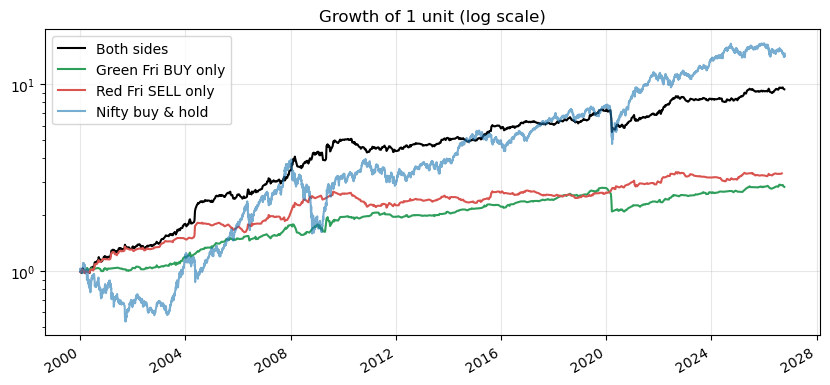

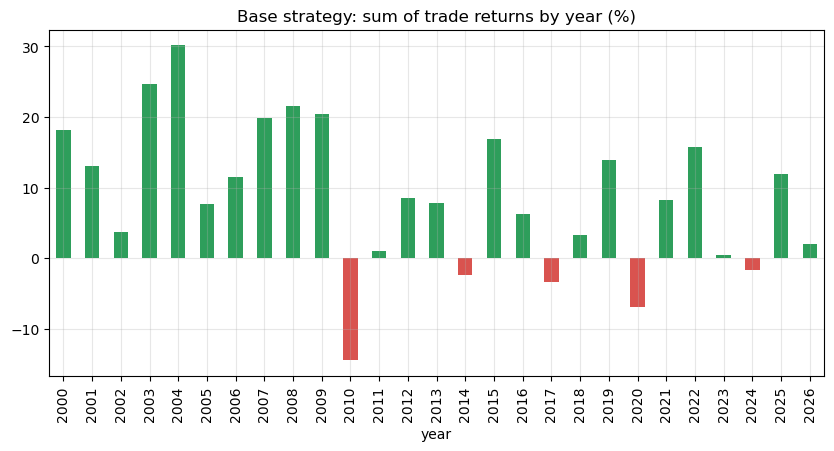

In [7]:
bh = d.set_index("Date").Close
bh = bh / bh.iloc[0]

fig, ax = plt.subplots()
for name, r_, c in [("Both sides", both_all, "k"), ("Green Fri BUY only", green_all, "#2e9e5b"), ("Red Fri SELL only", red_all, "#d9534f")]:
    ((1 + r_ / 100).cumprod()).plot(ax=ax, label=name, color=c)
bh.plot(ax=ax, label="Nifty buy & hold", color="#1f77b4", alpha=0.6)
ax.set_yscale("log"); ax.legend(); ax.set_title("Growth of 1 unit (log scale)"); ax.set_xlabel("")
plt.show()

by_year = w.groupby("year").agg(trades=("net_ret", "size"), win_pct=("win", lambda x: x.mean() * 100), avg_ret=("net_ret", "mean"), total_ret=("net_ret", "sum")).round(2)
by_year["total_ret"].plot.bar(color=np.where(by_year.total_ret >= 0, "#2e9e5b", "#d9534f"), title="Base strategy: sum of trade returns by year (%)")
plt.show()

**Important benchmark:** the last row ("BUY every Friday") ignores Friday's colour completely. Any real colour edge has to beat it. Notice its win rate can look decent (the market rises more often than it falls) while its average return is about zero, so judge the strategies by **average return per trade**, not win rate alone.

**How to read this:** the table shows the raw edge per trade. Watch two numbers: the **average return per trade** (this is what costs have to be smaller than) and the **p-value** (small = unlikely to be luck). The log chart shows whether the equity line grows steadily or in a few jumps. The yearly bars show which years carried the result.

## 4. Which factors could give an edge?

The idea behind a factor like **"red Friday + Friday volume > Thursday volume"**: rising volume suggests real participation behind Friday's move, so it is more likely to continue on Monday. A move on fading volume lacks conviction and is more likely to bounce.

We test a set of similar factors, for each side separately. To keep them comparable, all factors are measured **in the direction of Friday's colour**:

- `close_strength`: 1 means Friday closed right at its extreme in its own direction (green at the high, red at the low)
- `gap_aligned`, `trend_aligned`, `mom5_aligned`: positive means the factor points the same way as Friday's colour

### 4a. Rank correlation (Spearman) of each factor with the outcome

Spearman looks at "does a higher factor value go with a higher outcome?" without assuming a straight line. `r_follow` is against Monday same-colour (0/1), `r_return` against the trade return.

**Beware multiple testing:** we run about 16 tests per side. At p < 0.05, roughly one will look significant by pure chance. Treat anything with p above ~0.003 (Bonferroni level) as a hint, not proof.

In [8]:
NUM_FEATURES = ["volchg1", "relvol20", "body_size", "gap_aligned",
                "close_strength", "range_rel20", "trend_aligned", "mom5_aligned"]

def spearman_table(side):
    sub = w[w.colour == side]
    rows = []
    for f in NUM_FEATURES:
        s = sub[[f, "follow", "net_ret"]].dropna()
        r1, p1 = stats.spearmanr(s[f], s.follow.astype(int))
        r2, p2 = stats.spearmanr(s[f], s.net_ret)
        rows.append(dict(feature=f, n=len(s), r_follow=r1, p_follow=p1, r_return=r2, p_return=p2))
    return pd.DataFrame(rows).set_index("feature").round(3)

print("GREEN Fridays"); display(spearman_table("green"))
print("RED Fridays");   display(spearman_table("red"))

GREEN Fridays


,n,r_follow,p_follow,r_return,p_return
feature,,,,,
volchg1,583,-0.009,0.820,-0.043,0.299
relvol20,573,0.012,0.779,-0.006,0.886
body_size,583,0.101,0.015,0.138,0.001
gap_aligned,583,0.001,0.987,0.028,0.506
close_strength,583,0.100,0.016,0.099,0.017
range_rel20,581,-0.002,0.966,0.004,0.916
trend_aligned,579,0.024,0.571,0.063,0.129
mom5_aligned,583,0.066,0.109,0.119,0.004


RED Fridays


,n,r_follow,p_follow,r_return,p_return
feature,,,,,
volchg1,577,0.105,0.011,0.143,0.001
relvol20,564,-0.006,0.890,-0.002,0.957
body_size,577,0.067,0.109,0.116,0.005
gap_aligned,577,0.017,0.677,0.087,0.037
close_strength,577,0.087,0.036,0.118,0.004
range_rel20,575,-0.006,0.889,0.007,0.865
trend_aligned,571,0.012,0.782,0.040,0.335
mom5_aligned,576,0.040,0.338,0.064,0.127


### 4b. Quintile view: does the win rate change as the factor rises?

Each factor is split into 5 equal buckets (Q1 = lowest values, Q5 = highest). The dashed line is the win rate of all trades on that side. A real factor shows a steady slope or one bucket that clearly stands out. A random zig-zag means noise.

,trades,follow_pct,win_pct,avg_ret
RED Friday: volchg1 bucket,,,,
Q1,116,43.10,37.07,-0.24
Q2,115,53.04,49.57,0.10
Q3,115,60.00,61.74,0.44
Q4,115,54.78,55.65,0.49
Q5,116,60.34,52.59,0.30


,trades,follow_pct,win_pct,avg_ret
GREEN Friday: volchg1 bucket,,,,
Q1,117,57.26,66.67,0.24
Q2,116,53.45,59.48,0.19
Q3,117,55.56,64.96,0.23
Q4,116,56.03,60.34,0.21
Q5,117,53.85,55.56,0.08


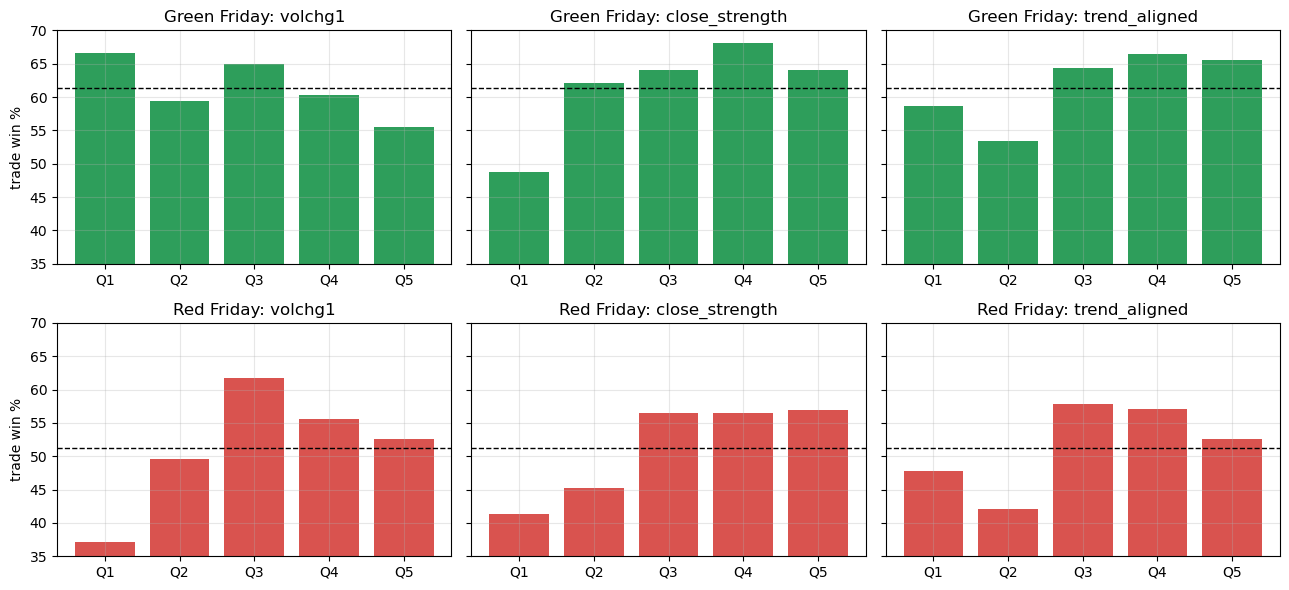

In [9]:
def quintile_table(side, feature, q=5):
    sub = w[w.colour == side].dropna(subset=[feature]).copy()
    sub["bucket"] = "Q" + (pd.qcut(sub[feature], q, labels=False, duplicates="drop") + 1).astype(str)
    return sub.groupby("bucket").agg(
        trades=("net_ret", "size"),
        follow_pct=("follow", lambda x: x.mean() * 100),
        win_pct=("win", lambda x: x.mean() * 100),
        avg_ret=("net_ret", "mean"),
    ).round(2)

display(quintile_table("red", "volchg1").rename_axis("RED Friday: volchg1 bucket"))
display(quintile_table("green", "volchg1").rename_axis("GREEN Friday: volchg1 bucket"))

plot_feats = ["volchg1", "close_strength", "trend_aligned"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for i, side in enumerate(["green", "red"]):
    base_win = w[w.colour == side].win.mean() * 100
    for j, f in enumerate(plot_feats):
        qt = quintile_table(side, f)
        axes[i, j].bar(qt.index, qt.win_pct, color="#2e9e5b" if side == "green" else "#d9534f")
        axes[i, j].axhline(base_win, ls="--", c="k", lw=1)
        axes[i, j].set_title(f"{side.title()} Friday: {f}"); axes[i, j].set_ylim(35, 70)
axes[0, 0].set_ylabel("trade win %"); axes[1, 0].set_ylabel("trade win %")
plt.tight_layout(); plt.show()

### 4c. Simple yes/no filters (including *Friday volume > Thursday volume*)

Each filter is a yes/no rule. For every filter we compare trades where it is **true** vs **false**:

- `win_yes` / `win_no`: win rate when the filter is on / off
- `p_win`: Fisher exact test on those win rates
- `p_ret`: Welch t-test on the average returns
- `win_yes_H1` / `win_yes_H2`: the win rate of the "yes" group in the first half (up to `SPLIT_YEAR`) and in the second half. **A real edge should look similar in both halves.**

In [10]:
def make_filters(sub):
    """Boolean columns, one per candidate filter. Missing data counts as False."""
    return pd.DataFrame({
        "vol_up (Fri vol > Thu vol)":    sub.Volume > sub.prev_vol,
        "relvol20 > 1":                  sub.relvol20 > 1,
        "strong close (near extreme)":   sub.close_strength > 0.75,
        "big body (> 0.5%)":             sub.body_size > 0.5,
        "gap in Friday's direction":     sub.gap_aligned > 0,
        "trend aligned (vs 50DMA)":      sub.trend_aligned > 0,
        "5d momentum aligned":           sub.mom5_aligned > 0,
        "wide range (> 20d avg)":        sub.range_rel20 > 1,
        "Thursday same colour":          sub.thu_same,
    }, index=sub.index)

def filter_report(side):
    sub = w[w.colour == side]
    F = make_filters(sub)
    h1 = sub.year <= SPLIT_YEAR
    rows = []
    for name in F.columns:
        m = F[name]
        y, n = sub[m], sub[~m]
        if len(y) < 10 or len(n) < 10:
            continue
        p_win = stats.fisher_exact([[y.win.sum(), len(y) - y.win.sum()], [n.win.sum(), len(n) - n.win.sum()]])[1]
        p_ret = stats.ttest_ind(y.net_ret, n.net_ret, equal_var=False).pvalue
        rows.append({
            "filter": name, "n_yes": len(y),
            "win_yes": y.win.mean() * 100, "win_no": n.win.mean() * 100,
            "avg_yes": y.net_ret.mean(), "avg_no": n.net_ret.mean(),
            "p_win": p_win, "p_ret": p_ret,
            "win_yes_H1": sub[m & h1].win.mean() * 100, "win_yes_H2": sub[m & ~h1].win.mean() * 100,
        })
    out = pd.DataFrame(rows).set_index("filter").round(3)
    base = f"{side.title()} Fridays: baseline win {sub.win.mean()*100:.1f}%, avg {sub.net_ret.mean():.3f}%, n={len(sub)}"
    return base, out

for side in ["red", "green"]:
    base, out = filter_report(side)
    print(base)
    display(out.sort_values("p_ret"))

Red Fridays: baseline win 51.3%, avg 0.220%, n=577


,n_yes,win_yes,win_no,avg_yes,avg_no,p_win,p_ret,win_yes_H1,win_yes_H2
filter,,,,,,,,,
vol_up (Fri vol > Thu vol),261,55.172,48.101,0.394,0.077,0.095,0.016,62.617,50.000
big body (> 0.5%),319,52.665,49.612,0.345,0.066,0.503,0.026,53.073,52.143
5d momentum aligned,346,55.202,45.455,0.325,0.063,0.022,0.033,56.395,54.023
trend aligned (vs 50DMA),254,55.512,47.988,0.382,0.093,0.078,0.034,56.716,54.167
strong close (near extreme),304,57.566,44.322,0.347,0.080,0.002,0.037,58.000,57.143
gap in Friday's direction,238,52.521,50.442,0.320,0.151,0.672,0.218,49.593,55.652
wide range (> 20d avg),292,49.658,52.982,0.275,0.164,0.454,0.388,51.389,47.973
Thursday same colour,294,51.701,50.883,0.251,0.188,0.868,0.624,57.037,47.170
relvol20 > 1,284,51.056,51.536,0.215,0.226,0.934,0.934,50.806,51.250


Green Fridays: baseline win 61.4%, avg 0.190%, n=583


,n_yes,win_yes,win_no,avg_yes,avg_no,p_win,p_ret,win_yes_H1,win_yes_H2
filter,,,,,,,,,
5d momentum aligned,418,65.072,52.121,0.342,-0.194,0.005,0.001,64.414,65.816
big body (> 0.5%),315,66.032,55.970,0.315,0.044,0.013,0.030,65.025,67.857
trend aligned (vs 50DMA),392,63.520,57.068,0.280,0.006,0.147,0.076,60.825,66.162
strong close (near extreme),371,66.307,52.830,0.260,0.067,0.001,0.105,66.146,66.480
gap in Friday's direction,365,63.836,57.339,0.246,0.096,0.135,0.251,61.413,66.298
wide range (> 20d avg),228,61.404,61.408,0.101,0.248,1.000,0.276,61.947,60.870
relvol20 > 1,297,62.290,60.490,0.127,0.256,0.671,0.320,62.963,61.481
vol_up (Fri vol > Thu vol),250,57.200,64.565,0.129,0.236,0.072,0.441,60.294,53.509
Thursday same colour,288,63.194,59.661,0.233,0.148,0.396,0.515,61.988,64.957


### 4d. Combining filters, with an honest out-of-sample check

Single filters may be weak, but a combination might work. The danger is **data snooping**: if we try many combinations and pick the best, it will look great on the same data we searched.

To stay honest:

1. Search all combinations of up to 3 filters using **only the first half** of the data (`<= SPLIT_YEAR`)
2. Rank them by their average return in that first half
3. Then look at the **second half** (`H2`), which the search never saw

If a rule is good in H1 but falls apart in H2, it was an artefact. Only rules that hold up in H2 deserve attention.

In [11]:
def combo_search(side, max_k=3, min_n=25):
    sub = w[w.colour == side]
    F = make_filters(sub)
    h1 = sub.year <= SPLIT_YEAR
    h2 = ~h1
    rows = []
    for k in range(1, max_k + 1):
        for combo in itertools.combinations(F.columns, k):
            m = F[list(combo)].all(axis=1)
            a, b = m & h1, m & h2
            if a.sum() < min_n or b.sum() < min_n:
                continue
            rows.append(dict(rule=" & ".join(combo), n_all=int(m.sum()),
                             win_all=sub.win[m].mean() * 100, avg_all=sub.net_ret[m].mean(),
                             n_H1=int(a.sum()), win_H1=sub.win[a].mean() * 100, avg_H1=sub.net_ret[a].mean(),
                             n_H2=int(b.sum()), win_H2=sub.win[b].mean() * 100, avg_H2=sub.net_ret[b].mean()))
    return pd.DataFrame(rows).sort_values("avg_H1", ascending=False).round(2)

for side in ["red", "green"]:
    sub = w[w.colour == side]
    h1 = sub.year <= SPLIT_YEAR
    print(f"{side.upper()} Fridays  | baseline  H1: win {sub[h1].win.mean()*100:.1f}%, avg {sub[h1].net_ret.mean():.2f}%   "
          f"H2: win {sub[~h1].win.mean()*100:.1f}%, avg {sub[~h1].net_ret.mean():.2f}%")
    with pd.option_context("display.max_colwidth", 90, "display.width", 250):
        display(combo_search(side).head(8).set_index("rule"))

RED Fridays  | baseline  H1: win 53.1%, avg 0.34%   H2: win 49.7%, avg 0.11%


,n_all,win_all,avg_all,n_H1,win_H1,avg_H1,n_H2,win_H2,avg_H2
rule,,,,,,,,,
vol_up (Fri vol > Thu vol) & strong close (near extreme) & trend aligned (vs 50DMA),74,66.22,0.91,36,75.00,1.64,38,57.89,0.22
vol_up (Fri vol > Thu vol) & strong close (near extreme) & Thursday same colour,73,63.01,0.79,32,75.00,1.54,41,53.66,0.20
vol_up (Fri vol > Thu vol) & strong close (near extreme) & 5d momentum aligned,100,64.00,0.74,45,71.11,1.45,55,58.18,0.16
vol_up (Fri vol > Thu vol) & strong close (near extreme) & wide range (> 20d avg),104,60.58,0.66,46,67.39,1.27,58,55.17,0.18
strong close (near extreme) & trend aligned (vs 50DMA) & wide range (> 20d avg),100,62.00,0.77,57,66.67,1.20,43,55.81,0.19
vol_up (Fri vol > Thu vol) & trend aligned (vs 50DMA) & wide range (> 20d avg),87,55.17,0.70,45,60.00,1.19,42,50.00,0.17
vol_up (Fri vol > Thu vol) & strong close (near extreme) & big body (> 0.5%),116,62.93,0.71,56,67.86,1.18,60,58.33,0.26
vol_up (Fri vol > Thu vol) & relvol20 > 1 & strong close (near extreme),99,60.61,0.63,44,65.91,1.17,55,56.36,0.20


GREEN Fridays  | baseline  H1: win 59.7%, avg 0.25%   H2: win 63.2%, avg 0.13%


,n_all,win_all,avg_all,n_H1,win_H1,avg_H1,n_H2,win_H2,avg_H2
rule,,,,,,,,,
vol_up (Fri vol > Thu vol) & strong close (near extreme) & big body (> 0.5%),119,64.71,0.37,73,69.86,0.69,46,56.52,-0.15
big body (> 0.5%) & gap in Friday's direction & trend aligned (vs 50DMA),131,73.28,0.53,80,72.50,0.67,51,74.51,0.32
vol_up (Fri vol > Thu vol) & big body (> 0.5%) & trend aligned (vs 50DMA),98,67.35,0.54,62,67.74,0.65,36,66.67,0.34
strong close (near extreme) & big body (> 0.5%) & gap in Friday's direction,173,72.25,0.45,99,71.72,0.65,74,72.97,0.18
big body (> 0.5%) & gap in Friday's direction & 5d momentum aligned,162,72.22,0.54,96,71.88,0.64,66,72.73,0.40
strong close (near extreme) & gap in Friday's direction & trend aligned (vs 50DMA),168,72.62,0.44,75,73.33,0.64,93,72.04,0.28
vol_up (Fri vol > Thu vol) & strong close (near extreme) & gap in Friday's direction,102,65.69,0.30,53,69.81,0.62,49,61.22,-0.06
vol_up (Fri vol > Thu vol) & strong close (near extreme) & trend aligned (vs 50DMA),115,66.96,0.44,61,70.49,0.62,54,62.96,0.24


**How to read this:** compare `win_H1` / `avg_H1` (where the rule was *found*) against `win_H2` / `avg_H2` (where it was *tested*). Look for rules where H2 is still clearly better than the baseline printed above the table. If H2 collapses toward the baseline, the rule was probably a fluke.

### 4e. Does candle body size matter?

Here we look at Friday's **body size** (|close − open| in %) on its own, because it is an easy rule to apply.

1. **Quintiles:** does follow-through rise as the body gets bigger?
2. **Threshold sweep:** "only trade if the body is at least X%". For each X we show the trade count, win rate and average return, split into first half (H1) and second half (H2). A good threshold should help in **both** halves.
3. **Relative size:** the same idea, but measuring today's body against the average body of the last 20 days (`body_rel20`). A 0.6% candle is big in a quiet market and small in a volatile one.

Watch the `trades` and `n_H2` columns. As the threshold rises, fewer trades remain, so the numbers get less reliable.

=== GREEN Fridays: baseline follow 55.2%, win 61.4%, avg 0.190% (n=583)
Tiny body (< 0.25%): n=141, follow 51.8%, win 56.0%, avg 0.086%
Quintiles of body_size:


,trades,follow_pct,win_pct,avg_ret
bucket,,,,
Q1,117,51.28,54.70,0.04
Q2,116,53.45,62.07,0.13
Q3,117,47.01,58.12,0.08
Q4,116,63.79,69.83,0.33
Q5,117,60.68,62.39,0.37


Quintiles of body_rel20 (today's body vs 20-day average body):


,trades,follow_pct,win_pct,avg_ret
bucket,,,,
Q1,117,50.43,52.14,0.01
Q2,116,44.83,57.76,0.05
Q3,116,59.48,64.66,0.14
Q4,116,66.38,70.69,0.51
Q5,116,56.03,62.93,0.25


Only trade if body >= threshold:


...

,trades,follow_pct,win_pct,avg_ret
bucket,,,,
Q1,116,43.97,43.10,-0.13
Q2,115,64.35,56.52,0.25
Q3,115,56.52,53.91,0.22
Q4,115,45.22,46.09,0.20
Q5,116,61.21,56.90,0.57


Quintiles of body_rel20 (today's body vs 20-day average body):


,trades,follow_pct,win_pct,avg_ret
bucket,,,,
Q1,115,45.22,46.09,-0.06
Q2,115,60.87,55.65,0.26
Q3,115,54.78,48.70,0.19
Q4,115,49.57,47.83,0.06
Q5,115,60.87,58.26,0.63


Only trade if body >= threshold:


,trades,follow_pct,win_pct,avg_ret,win_H1,win_H2,avg_H1,avg_H2,n_H2
min_body_pct,,,,,,,,,
0.00,577,54.25,51.30,0.22,53.14,49.67,0.34,0.11,306
0.25,447,57.05,53.24,0.31,54.02,52.47,0.42,0.19,223
0.50,319,54.23,52.66,0.34,53.07,52.14,0.49,0.16,140
0.75,239,53.56,51.46,0.38,51.59,51.22,0.49,0.17,82
1.00,175,60.00,57.71,0.54,52.80,70.00,0.57,0.47,50
1.50,98,62.24,59.18,0.64,55.26,72.73,0.70,0.43,22


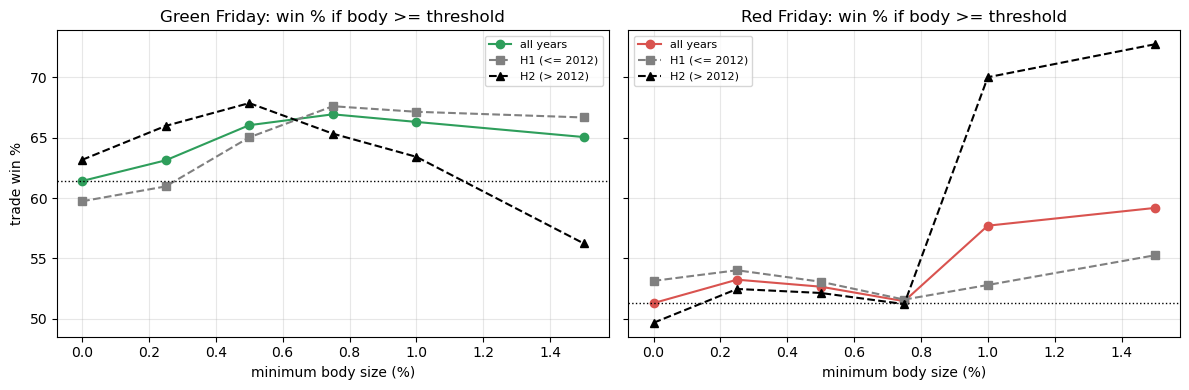

In [12]:
d["body_rel20"] = d.body_pct.abs() / d.body_pct.abs().rolling(20).mean().shift(1)
w["body_rel20"] = d.loc[w.index, "body_rel20"]

def body_sweep(side, thresholds=(0, 0.25, 0.5, 0.75, 1.0, 1.5)):
    s = w[w.colour == side]
    rows = []
    for t in thresholds:
        y = s[s.body_size >= t]
        h1, h2 = y[y.year <= SPLIT_YEAR], y[y.year > SPLIT_YEAR]
        rows.append(dict(min_body_pct=t, trades=len(y),
                         follow_pct=y.follow.mean() * 100, win_pct=y.win.mean() * 100, avg_ret=y.net_ret.mean(),
                         win_H1=h1.win.mean() * 100, win_H2=h2.win.mean() * 100,
                         avg_H1=h1.net_ret.mean(), avg_H2=h2.net_ret.mean(), n_H2=len(h2)))
    return pd.DataFrame(rows).set_index("min_body_pct").round(2)

for side in ["green", "red"]:
    s = w[w.colour == side]
    small = s[s.body_size < 0.25]
    print(f"=== {side.upper()} Fridays: baseline follow {s.follow.mean()*100:.1f}%, win {s.win.mean()*100:.1f}%, avg {s.net_ret.mean():.3f}% (n={len(s)})")
    print(f"Tiny body (< 0.25%): n={len(small)}, follow {small.follow.mean()*100:.1f}%, win {small.win.mean()*100:.1f}%, avg {small.net_ret.mean():.3f}%")
    print("Quintiles of body_size:");   display(quintile_table(side, "body_size"))
    print("Quintiles of body_rel20 (today's body vs 20-day average body):"); display(quintile_table(side, "body_rel20"))
    print("Only trade if body >= threshold:"); display(body_sweep(side))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, side, c in zip(axes, ["green", "red"], ["#2e9e5b", "#d9534f"]):
    sw = body_sweep(side)
    ax.plot(sw.index, sw.win_pct, marker="o", color=c, label="all years")
    ax.plot(sw.index, sw.win_H1, marker="s", ls="--", color="grey", label=f"H1 (<= {SPLIT_YEAR})")
    ax.plot(sw.index, sw.win_H2, marker="^", ls="--", color="k", label=f"H2 (> {SPLIT_YEAR})")
    ax.axhline(w[w.colour == side].win.mean() * 100, ls=":", c="k", lw=1)
    ax.set_title(f"{side.title()} Friday: win % if body >= threshold"); ax.set_xlabel("minimum body size (%)"); ax.legend(fontsize=8)
axes[0].set_ylabel("trade win %")
plt.tight_layout(); plt.show()

**How to read this:** the dotted line is the baseline win rate for that side. If the all-years line rises with the threshold *and* both the H1 and H2 lines sit above the dotted line, body size is a stable factor. If H2 drops back toward the dotted line, or the sample at high thresholds is tiny (`n_H2`), the apparent gain is not reliable. Tiny candles (under about 0.25%) are worth watching: if their follow-through is at or below 50%, skipping them is the simplest way to use body size.

## 5. The filtered strategy

Choose which filters to apply to each side. A trade is only taken when **all** listed filters are true. Names come from `make_filters()`, and an empty list means "take every trade".

The defaults come from what section 4 showed:

- **Red Friday:** `vol_up` (Friday volume > Thursday volume), your original idea. Check its H1 vs H2 columns in 4c: if the improvement is only in H1, the volume rule has faded.
- **Green Friday:** `big body & gap in direction & trend aligned`. This combination stayed strong in **both** halves in 4d, unlike the volume-based green rules, which fell apart in H2.

**Honesty note:** picking the green rule because it held up in H2 uses H2 information, so it is no longer a clean out-of-sample test. Treat it as a hypothesis to confirm on future data.

,trades,win_pct,avg_ret_pct,compounded_pct,max_drawdown_pct,avg_H1,avg_H2,win_H1,win_H2
Base (all Fridays),1160.0,56.379,0.205,838.238,-24.282,0.291,0.122,56.591,56.176
Red vol_up only,844.0,59.479,0.253,658.414,-25.277,0.392,0.126,60.494,58.542
Green combo only,708.0,55.367,0.278,555.048,-16.470,0.418,0.141,57.550,53.221
Both filters (filtered),392.0,61.224,0.441,429.501,-9.231,0.745,0.163,66.845,56.098


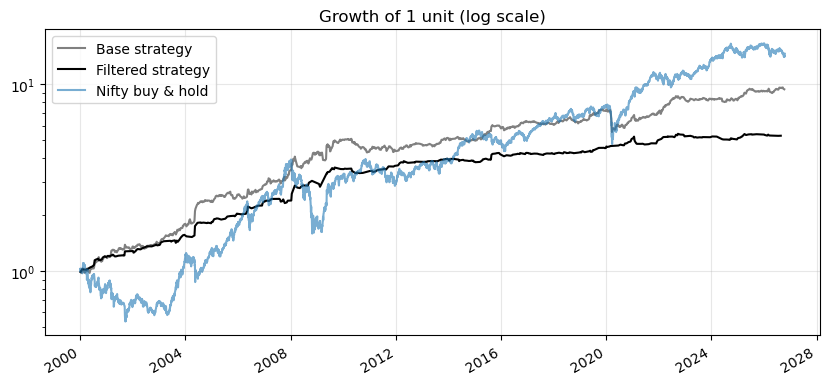

In [13]:
GREEN_RULE = ["big body (> 0.5%)", "gap in Friday's direction", "trend aligned (vs 50DMA)"]
RED_RULE   = ["vol_up (Fri vol > Thu vol)"]

def apply_rule(side, rule_names):
    sub = w[w.colour == side]
    if not rule_names:
        return sub
    F = make_filters(sub)
    return sub[F[rule_names].all(axis=1)]

def combine(green_rule, red_rule):
    return pd.concat([apply_rule("green", green_rule), apply_rule("red", red_rule)]).sort_index()

variants = {
    "Base (all Fridays)":      combine([], []),
    "Red vol_up only":         combine([], RED_RULE),
    "Green combo only":        combine(GREEN_RULE, []),
    "Both filters (filtered)": combine(GREEN_RULE, RED_RULE),
}

rows = {}
for name, t in variants.items():
    p = perf(t.set_index("Date").net_ret)
    h1, h2 = t[t.year <= SPLIT_YEAR], t[t.year > SPLIT_YEAR]
    p["avg_H1"], p["avg_H2"] = h1.net_ret.mean(), h2.net_ret.mean()
    p["win_H1"], p["win_H2"] = h1.win.mean() * 100, h2.win.mean() * 100
    rows[name] = p
display(pd.DataFrame(rows).T[["trades", "win_pct", "avg_ret_pct", "compounded_pct", "max_drawdown_pct",
                              "avg_H1", "avg_H2", "win_H1", "win_H2"]].round(3))

filtered = variants["Both filters (filtered)"]
filtered_ret = filtered.set_index("Date").net_ret

fig, ax = plt.subplots()
((1 + both_all / 100).cumprod()).plot(ax=ax, label="Base strategy", color="grey")
((1 + filtered_ret / 100).cumprod()).plot(ax=ax, label="Filtered strategy", color="k")
bh.plot(ax=ax, label="Nifty buy & hold", color="#1f77b4", alpha=0.6)
ax.set_yscale("log"); ax.legend(); ax.set_title("Growth of 1 unit (log scale)"); ax.set_xlabel("")
plt.show()

**Costs matter.** The table shows how the filtered strategy's win rate and average trade change as the round-trip cost rises. It uses the gross return, so it ignores `COST_PCT` set at the top.

In [14]:
cost_rows = []
for c in [0, 0.05, 0.10, 0.20, 0.30]:
    net = filtered.gross_ret - c
    cost_rows.append({"cost per trade %": c, "win %": (net > 0).mean() * 100,
                      "avg trade %": net.mean(), "total (sum of %)": net.sum()})
display(pd.DataFrame(cost_rows).set_index("cost per trade %").round(2))

,win %,avg trade %,total (sum of %)
cost per trade %,,,
0.00,61.22,0.44,172.79
0.05,58.67,0.39,153.19
0.10,55.61,0.34,133.59
0.20,50.77,0.24,94.39
0.30,47.70,0.14,55.19


## 6. Five-year blocks vs Nifty buy-and-hold

Blocks are calendar years: **2005-10** = Jan 2005 to Dec 2009, **2010-15** = 2010 to 2014, and so on. A final partial block (2025 to latest data) is added for completeness.

- **Buy & hold** = Nifty close at the end of the block vs the last close before the block started (price index, no dividends)
- **Strategy** = compounded return of the trades whose Friday falls inside the block, 1 unit of capital per trade
- **Exposure %** = share of trading days the strategy actually holds a position. The strategy is in the market only Friday close to Monday close, so most of the time capital is idle. That matters when comparing it with buy-and-hold.

Edit `PERIODS` to change the blocks.

period,2005-10,2010-15,2015-20,2020-25,2025-now
Nifty B&H %,150.0,59.3,46.9,94.3,-2.1
Base %,112.0,-0.7,43.3,14.1,14.5
Filtered %,91.9,9.5,18.3,11.2,4.7
B&H max DD %,-59.9,-28.0,-22.5,-38.4,-15.6
Base max DD %,-13.4,-15.4,-7.4,-24.3,-5.3
Filtered max DD %,-7.0,-5.4,-4.0,-9.2,-2.2
Base trades,213.0,217.0,216.0,218.0,74.0
Base win %,60.1,51.2,60.2,51.4,56.8
Filtered trades,70.0,69.0,82.0,73.0,19.0
Filtered win %,70.0,56.5,59.8,50.7,57.9


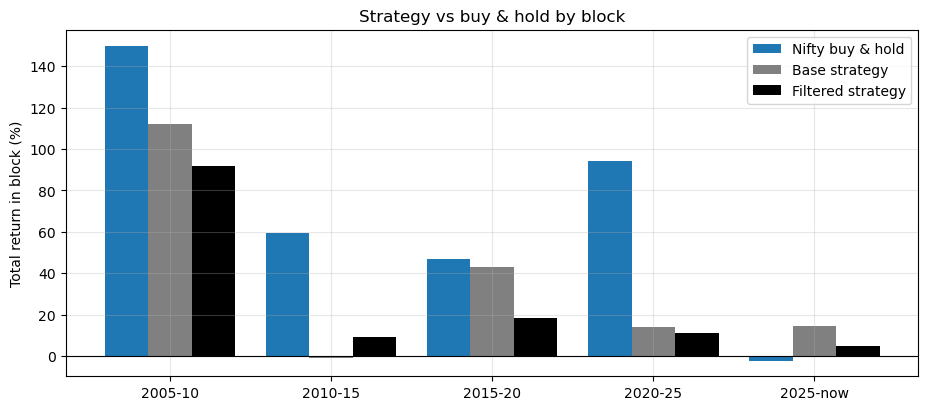

In [15]:
PERIODS = [("2005-10", 2005, 2009), ("2010-15", 2010, 2014), ("2015-20", 2015, 2019),
           ("2020-25", 2020, 2024), ("2025-now", 2025, 2026)]

def block_stats(start, end, trades_ret):
    seg  = d[(d.Date >= f"{start}-01-01") & (d.Date <= f"{end}-12-31")]
    prev = d[d.Date < f"{start}-01-01"].Close
    base = prev.iloc[-1] if len(prev) else seg.Close.iloc[0]
    curve = pd.concat([pd.Series([1.0]), (seg.Close / base).reset_index(drop=True)])
    r = trades_ret[(trades_ret.index.year >= start) & (trades_ret.index.year <= end)]
    eq = (1 + r / 100).cumprod()
    return dict(
        bh_ret=(seg.Close.iloc[-1] / base - 1) * 100,
        bh_maxdd=(curve / curve.cummax() - 1).min() * 100,
        strat_ret=(eq.iloc[-1] - 1) * 100 if len(r) else np.nan,
        strat_maxdd=(eq / eq.cummax() - 1).min() * 100 if len(r) else np.nan,
        trades=len(r), win_pct=(r > 0).mean() * 100 if len(r) else np.nan,
        avg_trade=r.mean() if len(r) else np.nan,
        exposure_pct=len(r) / len(seg) * 100,
    )

rows = []
for label, s, e in PERIODS:
    b = block_stats(s, e, both_all)
    f = block_stats(s, e, filtered_ret)
    rows.append({"period": label,
                 "Nifty B&H %": b["bh_ret"], "Base %": b["strat_ret"], "Filtered %": f["strat_ret"],
                 "B&H max DD %": b["bh_maxdd"], "Base max DD %": b["strat_maxdd"], "Filtered max DD %": f["strat_maxdd"],
                 "Base trades": b["trades"], "Base win %": b["win_pct"], "Filtered trades": f["trades"], "Filtered win %": f["win_pct"],
                 "Filtered avg trade %": f["avg_trade"], "Filtered exposure %": f["exposure_pct"]})
blocks = pd.DataFrame(rows).set_index("period").round(1)
display(blocks.T)

x = np.arange(len(blocks)); wd = 0.27
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - wd, blocks["Nifty B&H %"], wd, label="Nifty buy & hold", color="#1f77b4")
ax.bar(x,      blocks["Base %"],      wd, label="Base strategy", color="grey")
ax.bar(x + wd, blocks["Filtered %"],  wd, label="Filtered strategy", color="k")
ax.set_xticks(x); ax.set_xticklabels(blocks.index); ax.axhline(0, c="k", lw=0.8)
ax.set_ylabel("Total return in block (%)"); ax.legend(); ax.set_title("Strategy vs buy & hold by block")
plt.show()

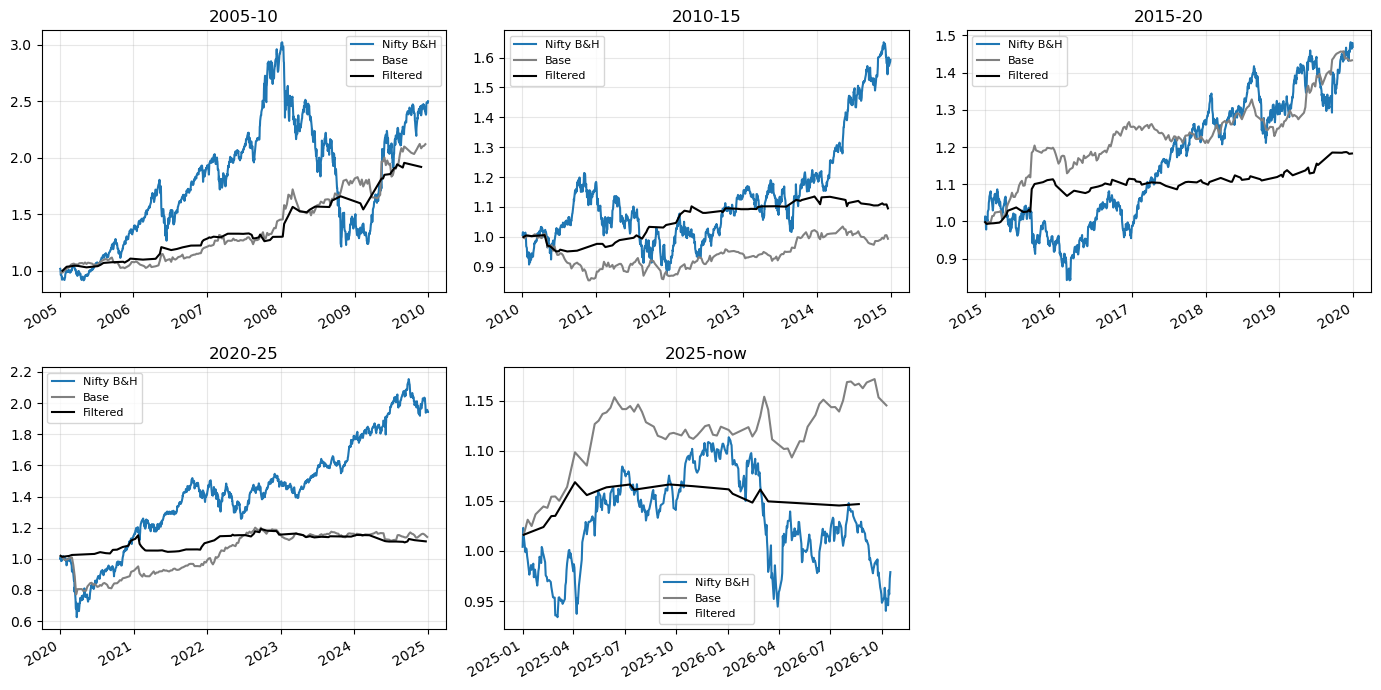

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, (label, s, e) in zip(axes, PERIODS):
    seg = d[(d.Date >= f"{s}-01-01") & (d.Date <= f"{e}-12-31")].set_index("Date")
    prev = d[d.Date < f"{s}-01-01"].Close
    base = prev.iloc[-1] if len(prev) else seg.Close.iloc[0]
    (seg.Close / base).plot(ax=ax, color="#1f77b4", label="Nifty B&H")
    for name, r_, c in [("Base", both_all, "grey"), ("Filtered", filtered_ret, "k")]:
        rr = r_[(r_.index.year >= s) & (r_.index.year <= e)]
        ((1 + rr / 100).cumprod()).plot(ax=ax, color=c, label=name)
    ax.set_title(label); ax.set_xlabel(""); ax.legend(fontsize=8)
for ax in axes[len(PERIODS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**How to read this:** the strategy is in the market only a fraction of the time, so a smaller headline return than buy-and-hold is not automatically bad. Look at three things per block: (1) is the strategy's return positive, (2) is the average trade bigger than your trading costs, (3) is the drawdown lower than buy-and-hold's. A strategy that wins in one block but loses in the others is not stable.

## 7. Summary

The cell below prints the key numbers from this run, so the text always matches your data.

In [17]:
g = w[w.colour == "green"]; r = w[w.colour == "red"]
rv = apply_rule("red", RED_RULE)
h1r = r.year <= SPLIT_YEAR; h1v = rv.year <= SPLIT_YEAR

print(f"1) Green Friday -> green Monday: {(g.mon_colour=='green').mean()*100:.1f}%  (all Mondays green: {all_mondays_green:.1f}%)")
print(f"   Red Friday   -> red Monday:   {(r.mon_colour=='red').mean()*100:.1f}%  (all Mondays red:   {100-all_mondays_green:.1f}%)")
print(f"   Chi-square independence test p = {p_chi:.4f}")
print()
print(f"2) Base strategy: {len(w)} trades, win {w.win.mean()*100:.1f}%, avg {w.net_ret.mean():.3f}% per trade (cost {COST_PCT}%)")
print(f"   Green BUY avg {g.net_ret.mean():.3f}%   |   Red SELL avg {r.net_ret.mean():.3f}%")
print()
print(f"3) Red Friday with volume > Thursday: {len(rv)} trades, win {rv.win.mean()*100:.1f}%, avg {rv.net_ret.mean():.3f}%")
print(f"   vs all red Fridays:                {len(r)} trades, win {r.win.mean()*100:.1f}%, avg {r.net_ret.mean():.3f}%")
print(f"   First half  (<= {SPLIT_YEAR}): win {rv[h1v].win.mean()*100:.1f}%, avg {rv[h1v].net_ret.mean():.3f}%  ({h1v.sum()} trades)")
print(f"   Second half (>  {SPLIT_YEAR}): win {rv[~h1v].win.mean()*100:.1f}%, avg {rv[~h1v].net_ret.mean():.3f}%  ({(~h1v).sum()} trades)")
print()
gv = apply_rule("green", GREEN_RULE); h1g = gv.year <= SPLIT_YEAR
print(f"   Green Friday combo ({' & '.join(GREEN_RULE)}): {len(gv)} trades, win {gv.win.mean()*100:.1f}%, avg {gv.net_ret.mean():.3f}%  vs all green Fridays win {g.win.mean()*100:.1f}%, avg {g.net_ret.mean():.3f}%")
print(f"   First half: win {gv[h1g].win.mean()*100:.1f}% | Second half: win {gv[~h1g].win.mean()*100:.1f}%")
print()
print("4) Blocks where the filtered strategy was positive:",
      ", ".join(blocks.index[blocks["Filtered %"] > 0]) or "none")
print("   Blocks where it beat buy & hold:",
      ", ".join(blocks.index[blocks["Filtered %"] > blocks["Nifty B&H %"]]) or "none")

1) Green Friday -> green Monday: 55.2%  (all Mondays green: 50.8%)
   Red Friday   -> red Monday:   54.2%  (all Mondays red:   49.2%)
   Chi-square independence test p = 0.0015

2) Base strategy: 1160 trades, win 56.4%, avg 0.205% per trade (cost 0.0%)
   Green BUY avg 0.190%   |   Red SELL avg 0.220%

3) Red Friday with volume > Thursday: 261 trades, win 55.2%, avg 0.394%
   vs all red Fridays:                577 trades, win 51.3%, avg 0.220%
   First half  (<= 2012): win 62.6%, avg 0.800%  (107 trades)
   Second half (>  2012): win 50.0%, avg 0.112%  (154 trades)

   Green Friday combo (big body (> 0.5%) & gap in Friday's direction & trend aligned (vs 50DMA)): 131 trades, win 73.3%, avg 0.534%  vs all green Fridays win 61.4%, avg 0.190%
   First half: win 72.5% | Second half: win 74.5%

4) Blocks where the filtered strategy was positive: 2005-10, 2010-15, 2015-20, 2020-25, 2025-now
   Blocks where it beat buy & hold: 2025-now


### What to keep in mind

- **Costs decide everything.** The edge per trade is small. Set `COST_PCT` to a realistic round-trip cost for index futures (brokerage, STT, slippage) and re-run the notebook.
- **Check both halves.** Any rule that works only in the early data (before about 2013) should be treated with suspicion.
- **Many tests, few real effects.** We tested many factors on two sides. A few will look good by chance. Out-of-sample results (H2 columns) and stability across 5-year blocks matter more than a small p-value.
- **Idle capital.** The strategy holds a position only Friday close to Monday close. Buy-and-hold is always invested, so compare per-trade edge and drawdown, not just total return.
- **Options are a different problem.** Premium, weekend time decay and bid-ask spread all have to be beaten by this small index edge. Test with real option prices before using this idea there.
- This is analysis of past data, not financial advice.